# COVID-19 Clinical Trials: Exploratory Data Analysis

This notebook is the exploratory step of the project. Its cleaning rules were turned into the production ETL pipeline in `etl/` (see `etl/transform.py`), and its charts are served as JSON by the `/api/v1/analytics` endpoints.

Put the dataset at `data/COVID_clinical_trials.csv` before running.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
data = pd.read_csv('../data/COVID_clinical_trials.csv')

In [3]:
data.head(10)

,Rank,NCT Number,Title,Acronym,Status,Study Results,Conditions,Interventions,Outcome Measures,Sponsor/Collaborators,...,Other IDs,Start Date,Primary Completion Date,Completion Date,First Posted,Results First Posted,Last Update Posted,Locations,Study Documents,URL
0,1,NCT04785898,Diagnostic Performance of the ID Now™ COVID-19...,COVID-IDNow,"Active, not recruiting",No Results Available,Covid19,Diagnostic Test: ID Now™ COVID-19 Screening Test,Evaluate the diagnostic performance of the ID ...,Groupe Hospitalier Paris Saint Joseph,...,COVID-IDNow,"November 9, 2020","December 22, 2020","April 30, 2021","March 8, 2021",NaN,"March 8, 2021","Groupe Hospitalier Paris Saint-Joseph, Paris, ...",NaN,https://ClinicalTrials.gov/show/NCT04785898
1,2,NCT04595136,Study to Evaluate the Efficacy of COVID19-0001...,COVID-19,Not yet recruiting,No Results Available,SARS-CoV-2 Infection,Drug: Drug COVID19-0001-USR|Drug: normal saline,Change on viral load results from baseline aft...,United Medical Specialties,...,COVID19-0001-USR,"November 2, 2020","December 15, 2020","January 29, 2021","October 20, 2020",NaN,"October 20, 2020","Cimedical, Barranquilla, Atlantico, Colombia",NaN,https://ClinicalTrials.gov/show/NCT04595136
2,3,NCT04395482,Lung CT Scan Analysis of SARS-CoV2 Induced Lun...,TAC-COVID19,Recruiting,No Results Available,covid19,Other: Lung CT scan analysis in COVID-19 patients,A qualitative analysis of parenchymal lung dam...,University of Milano Bicocca,...,TAC-COVID19,"May 7, 2020","June 15, 2021","June 15, 2021","May 20, 2020",NaN,"November 9, 2020","Ospedale Papa Giovanni XXIII, Bergamo, Italy|P...",NaN,https://ClinicalTrials.gov/show/NCT04395482
3,4,NCT04416061,The Role of a Private Hospital in Hong Kong Am...,COVID-19,"Active, not recruiting",No Results Available,COVID,Diagnostic Test: COVID 19 Diagnostic Test,Proportion of asymptomatic subjects|Proportion...,Hong Kong Sanatorium & Hospital,...,RC-2020-08,"May 25, 2020","July 31, 2020","August 31, 2020","June 4, 2020",NaN,"June 4, 2020","Hong Kong Sanatorium & Hospital, Hong Kong, Ho...",NaN,https://ClinicalTrials.gov/show/NCT04416061
4,5,NCT04395924,Maternal-foetal Transmission of SARS-Cov-2,TMF-COVID-19,Recruiting,No Results Available,Maternal Fetal Infection Transmission|COVID-19...,Diagnostic Test: Diagnosis of SARS-Cov2 by RT-...,COVID-19 by positive PCR in cord blood and / o...,Centre Hospitalier Régional d'Orléans|Centre d...,...,CHRO-2020-10,"May 5, 2020",May 2021,May 2021,"May 20, 2020",NaN,"June 4, 2020","CHR Orléans, Orléans, France",NaN,https://ClinicalTrials.gov/show/NCT04395924
5,6,NCT04516954,Convalescent Plasma for COVID-19 Patients,CPCP,Enrolling by invitation,No Results Available,COVID 19,Biological: Convalescent COVID 19 Plasma,Evaluate the safety|Change in requirement for ...,Vinmec Research Institute of Stem Cell and Gen...,...,ISC.20.11.1,"August 1, 2020","November 30, 2020","December 30, 2020","August 18, 2020",NaN,"August 20, 2020",Vinmec Research Institute of Stem cell and Gen...,NaN,https://ClinicalTrials.gov/show/NCT04516954
6,7,NCT04476940,COVID-19 Breastfeeding Guideline for African-A...,COVID-BF,Not yet recruiting,No Results Available,Covid19|Exclusive Breastfeeding,Behavioral: COVID-19 Breastfeeding Support,COVID-19 breastfeeding guidance adherence at b...,Meharry Medical College,...,330875,September 2020,October 2021,June 2022,"July 20, 2020",NaN,"July 20, 2020","Meharry Medical College, Nashville, Tennessee,...",NaN,https://ClinicalTrials.gov/show/NCT04476940
7,8,NCT04634214,The Severity of COVID 19 in Diabetes and Non-d...,COVID19,Not yet recruiting,No Results Available,Covid19|Type2 Diabetes,NaN,Severity of COVID 19 among people with and wit...,India Diabetes Research Foundation & Dr. A. Ra...,...,IDRFARH015,"November 16, 2020","February 16, 2021","May 16, 2021","November 18, 2020",NaN,"November 18, 2020","Orthomed Hospital, Chennai, Tamil Nadu, India|...",NaN,https://ClinicalTrials.gov/show/NCT04634214
8,9,NCT04602884,Early Detection of COVID-19 Usi

In [4]:
data.shape

(5783, 27)

In [5]:
data.describe(include ='all')

,Rank,NCT Number,Title,Acronym,Status,Study Results,Conditions,Interventions,Outcome Measures,Sponsor/Collaborators,...,Other IDs,Start Date,Primary Completion Date,Completion Date,First Posted,Results First Posted,Last Update Posted,Locations,Study Documents,URL
count,5783.000000,5783,5783,2480,5783,5783,5783,4897,5748,5783,...,5782,5749,5747,5747,5783,36,5783,5198,182,5783
unique,NaN,5783,5775,2338,12,2,3067,4337,5687,3631,...,5734,654,877,978,438,33,269,4255,182,5783
top,NaN,NCT04785898,Study Assessing Vagus Nerve Stimulation in CoV...,COVID-19,Recruiting,No Results Available,COVID-19,Other: No intervention,Mortality,Assistance Publique - Hôpitaux de Paris,...,COVID-19,"May 1, 2020","December 31, 2020","December 31, 2021","April 24, 2020","November 4, 2020","April 8, 2021","Uhmontpellier, Montpellier, France","""Statistical Analysis Plan"", https://ClinicalT...",https://ClinicalTrials.gov/show/NCT04785898
freq,NaN,1,2,47,2805,5747,720,32,5,78,...,6,113,122,179,108,2,109,19,1,1
mean,2892.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,1669.552635,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,1446.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,2892.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,4337.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5783 entries, 0 to 5782
Data columns (total 27 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Rank                     5783 non-null   int64  
 1   NCT Number               5783 non-null   object 
 2   Title                    5783 non-null   object 
 3   Acronym                  2480 non-null   object 
 4   Status                   5783 non-null   object 
 5   Study Results            5783 non-null   object 
 6   Conditions               5783 non-null   object 
 7   Interventions            4897 non-null   object 
 8   Outcome Measures         5748 non-null   object 
 9   Sponsor/Collaborators    5783 non-null   object 
 10  Gender                   5773 non-null   object 
 11  Age                      5783 non-null   object 
 12  Phases                   3322 non-null   object 
 13  Enrollment               5749 non-null   float64
 14  Funded Bys              

In [7]:
data.isnull().sum()

Rank                          0
NCT Number                    0
Title                         0
Acronym                    3303
Status                        0
Study Results                 0
Conditions                    0
Interventions               886
Outcome Measures             35
Sponsor/Collaborators         0
Gender                       10
Age                           0
Phases                     2461
Enrollment                   34
Funded Bys                    0
Study Type                    0
Study Designs                35
Other IDs                     1
Start Date                   34
Primary Completion Date      36
Completion Date              36
First Posted                  0
Results First Posted       5747
Last Update Posted            0
Locations                   585
Study Documents            5601
URL                           0
dtype: int64

In [10]:
data.columns

Index(['Rank', 'NCT Number', 'Title', 'Acronym', 'Status', 'Study Results',
       'Conditions', 'Interventions', 'Outcome Measures',
       'Sponsor/Collaborators', 'Gender', 'Age', 'Phases', 'Enrollment',
       'Funded Bys', 'Study Type', 'Study Designs', 'Other IDs', 'Start Date',
       'Primary Completion Date', 'Completion Date', 'First Posted',
       'Results First Posted', 'Last Update Posted', 'Locations',
       'Study Documents', 'URL'],
      dtype='object')

In [11]:
# Categorical Features
data.select_dtypes(include = 'object').columns

Index(['NCT Number', 'Title', 'Acronym', 'Status', 'Study Results',
       'Conditions', 'Interventions', 'Outcome Measures',
       'Sponsor/Collaborators', 'Gender', 'Age', 'Phases', 'Funded Bys',
       'Study Type', 'Study Designs', 'Other IDs', 'Start Date',
       'Primary Completion Date', 'Completion Date', 'First Posted',
       'Results First Posted', 'Last Update Posted', 'Locations',
       'Study Documents', 'URL'],
      dtype='object')

In [12]:
# Numerical Features
data.select_dtypes(include = 'int').columns

Index(['Rank'], dtype='object')

In [13]:
# Numerical Features
data.select_dtypes(include = float).columns

Index(['Enrollment'], dtype='object')

In [14]:
# Detecting (Percentage) Missing Data
missing_data = data.isnull().mean() * 100
missing_data

Rank                        0.000000
NCT Number                  0.000000
Title                       0.000000
Acronym                    57.115684
Status                      0.000000
Study Results               0.000000
Conditions                  0.000000
Interventions              15.320768
Outcome Measures            0.605222
Sponsor/Collaborators       0.000000
Gender                      0.172921
Age                         0.000000
Phases                     42.555767
Enrollment                  0.587930
Funded Bys                  0.000000
Study Type                  0.000000
Study Designs               0.605222
Other IDs                   0.017292
Start Date                  0.587930
Primary Completion Date     0.622514
Completion Date             0.622514
First Posted                0.000000
Results First Posted       99.377486
Last Update Posted          0.000000
Locations                  10.115857
Study Documents            96.852845
URL                         0.000000
d

In [15]:
x=data['Enrollment'].median()
y=data['Enrollment'].mode()
z=data['Enrollment'].std()

print(x)
print(y)
print(z)

170.0
0    100.0
Name: Enrollment, dtype: float64
404543.7287841073


### **Dataset Overview**
- The dataset consists of 5783 entries and 27 columns. Below is a summary of the key columns and their descriptions:

**Column Analysis**
- **Rank, NCT Number, Title:** Metadata for each trial.
- **Acronym:** Missing for 57% of rows; categorical.
- **Status:** Contains 12 unique statuses like "Recruiting", "Completed", etc.
- **Study Results, Conditions, Interventions, Outcome Measures:** Provide detailed information about each trial.
- **Sponsor/Collaborators, Gender, Age:** Additional details about participants and sponsors.
- **Phases:** Missing for 42% of rows; defines trial phases.
- **Enrollment:** Numeric, missing for 0.6% of rows; highly skewed.
- **Dates:** Includes Start Date, Primary Completion Date, and Completion Date.
- **Locations, Study Documents:** Location data is partially missing (10%), and Study Documents has significant missingness (96.8%).
- **URL:** Unique for every trial.

In [16]:
data['Enrollment'] = data['Enrollment'].fillna(data['Enrollment'].median())

In [17]:
data.drop(columns=['Results First Posted','Study Documents'],inplace=True)

In [18]:
# Detecting (Percentage) Missing Data
missing_data = data.isnull().mean() * 100
missing_data

Rank                        0.000000
NCT Number                  0.000000
Title                       0.000000
Acronym                    57.115684
Status                      0.000000
Study Results               0.000000
Conditions                  0.000000
Interventions              15.320768
Outcome Measures            0.605222
Sponsor/Collaborators       0.000000
Gender                      0.172921
Age                         0.000000
Phases                     42.555767
Enrollment                  0.000000
Funded Bys                  0.000000
Study Type                  0.000000
Study Designs               0.605222
Other IDs                   0.017292
Start Date                  0.587930
Primary Completion Date     0.622514
Completion Date             0.622514
First Posted                0.000000
Last Update Posted          0.000000
Locations                  10.115857
URL                         0.000000
dtype: float64

In [19]:
print(f"Shape before dropping Null rows {data.shape}")
data.dropna(axis = 0 , thresh = 10 , inplace = True)
print(f"Shape after dropping Null rows {data.shape}")

Shape before dropping Null rows (5783, 25)
Shape after dropping Null rows (5783, 25)


In [20]:
data.isnull().sum()

Rank                          0
NCT Number                    0
Title                         0
Acronym                    3303
Status                        0
Study Results                 0
Conditions                    0
Interventions               886
Outcome Measures             35
Sponsor/Collaborators         0
Gender                       10
Age                           0
Phases                     2461
Enrollment                    0
Funded Bys                    0
Study Type                    0
Study Designs                35
Other IDs                     1
Start Date                   34
Primary Completion Date      36
Completion Date              36
First Posted                  0
Last Update Posted            0
Locations                   585
URL                           0
dtype: int64

In [21]:
data.isnull().mean() * 100

Rank                        0.000000
NCT Number                  0.000000
Title                       0.000000
Acronym                    57.115684
Status                      0.000000
Study Results               0.000000
Conditions                  0.000000
Interventions              15.320768
Outcome Measures            0.605222
Sponsor/Collaborators       0.000000
Gender                      0.172921
Age                         0.000000
Phases                     42.555767
Enrollment                  0.000000
Funded Bys                  0.000000
Study Type                  0.000000
Study Designs               0.605222
Other IDs                   0.017292
Start Date                  0.587930
Primary Completion Date     0.622514
Completion Date             0.622514
First Posted                0.000000
Last Update Posted          0.000000
Locations                  10.115857
URL                         0.000000
dtype: float64

In [22]:
# Impute missing values for numerical features
numerical_features = data.select_dtypes(include="int").columns

In [23]:
print("\nColumns with missing values (before imputation):")
print(data[numerical_features].isnull().sum())


Columns with missing values (before imputation):
Rank    0
dtype: int64


In [24]:
for feature in numerical_features:
    if data[feature].isnull().sum() > 0:
        data[feature] = data[feature].fillna(data[feature].median())

In [25]:
print("\nColumns with missing values (after imputation):")
print(data[numerical_features].isnull().sum())


Columns with missing values (after imputation):
Rank    0
dtype: int64


In [26]:
# Impute missing values for Categorical features
categorical_features = data.select_dtypes(include="object").columns

In [27]:
print("\nColumns with missing values (before imputation):")
print(data[categorical_features].isnull().sum())


Columns with missing values (before imputation):
NCT Number                    0
Title                         0
Acronym                    3303
Status                        0
Study Results                 0
Conditions                    0
Interventions               886
Outcome Measures             35
Sponsor/Collaborators         0
Gender                       10
Age                           0
Phases                     2461
Funded Bys                    0
Study Type                    0
Study Designs                35
Other IDs                     1
Start Date                   34
Primary Completion Date      36
Completion Date              36
First Posted                  0
Last Update Posted            0
Locations                   585
URL                           0
dtype: int64


In [28]:
for feature in categorical_features:
    if data[feature].isnull().sum() > 0:
        data[feature] = data[feature].fillna(f"Missing {feature}")

In [29]:
print("\nColumns with missing values (after imputation):")
print(data[categorical_features].isnull().sum())


Columns with missing values (after imputation):
NCT Number                 0
Title                      0
Acronym                    0
Status                     0
Study Results              0
Conditions                 0
Interventions              0
Outcome Measures           0
Sponsor/Collaborators      0
Gender                     0
Age                        0
Phases                     0
Funded Bys                 0
Study Type                 0
Study Designs              0
Other IDs                  0
Start Date                 0
Primary Completion Date    0
Completion Date            0
First Posted               0
Last Update Posted         0
Locations                  0
URL                        0
dtype: int64


<Axes: xlabel='Gender', ylabel='count'>

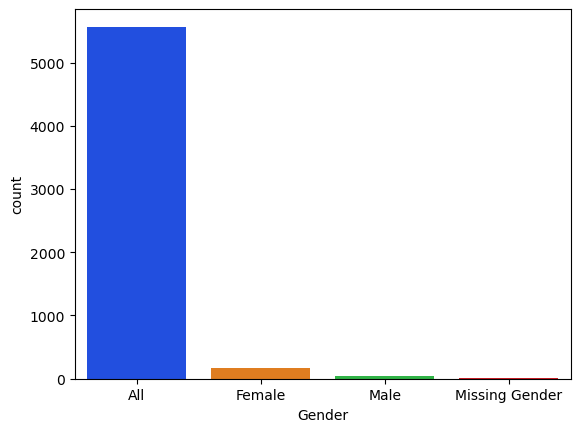

In [30]:
sns.countplot(x='Gender', data=data, palette = 'bright', hue= 'Gender')

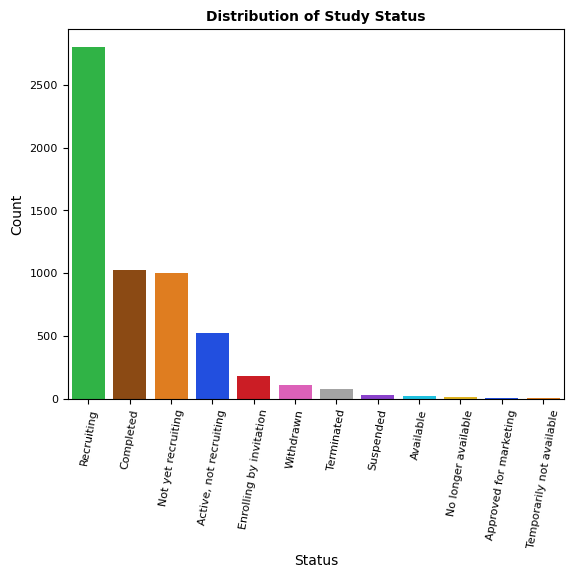

In [31]:
sns.countplot(data=data, x='Status', order=data['Status'].value_counts().index, palette='bright', hue='Status')
plt.title('Distribution of Study Status', fontsize=10, fontweight='bold')
plt.xlabel('Status', fontsize=10)
plt.ylabel('Count', fontsize=10)
plt.xticks(rotation=80, fontsize=8)  
plt.yticks(fontsize=8)
plt.show()

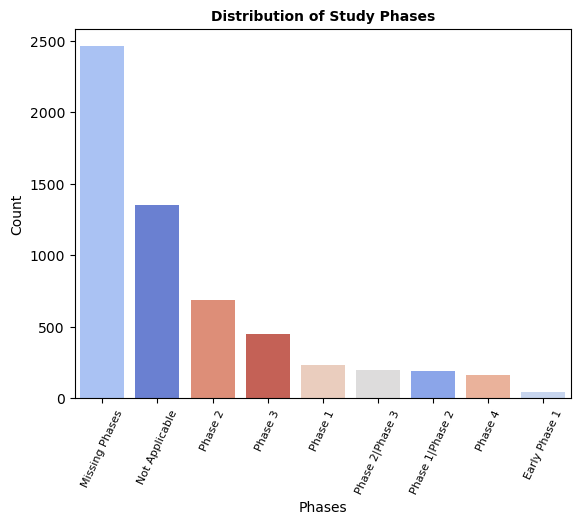

In [32]:
sns.countplot(data=data, x='Phases', order=data['Phases'].value_counts().index, palette='coolwarm', hue='Phases')
plt.title('Distribution of Study Phases', fontsize=10, fontweight='bold')
plt.xlabel('Phases', fontsize=10)
plt.ylabel('Count', fontsize=10)
plt.xticks(rotation=65, fontsize=8)
plt.show()

In [33]:
data['Study Type'].value_counts()

Study Type
Interventional                                                         3322
Observational                                                          2427
Expanded Access:Intermediate-size Population                             15
Expanded Access:Treatment IND/Protocol                                    8
Expanded Access:Intermediate-size Population|Treatment IND/Protocol       5
Expanded Access:Individual Patients                                       3
Expanded Access:Individual Patients|Intermediate-size Population          1
Expanded Access                                                           1
Expanded Access:Individual Patients|Treatment IND/Protocol                1
Name: count, dtype: int64

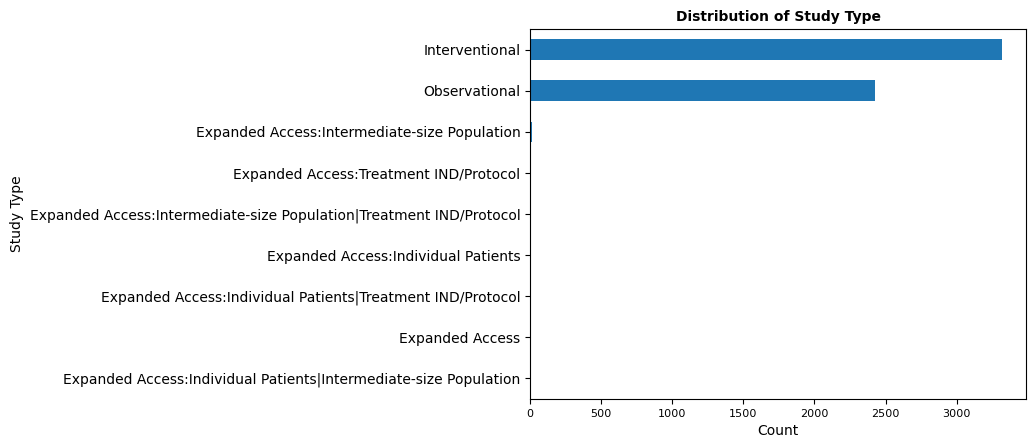

In [34]:
data['Study Type'].value_counts().sort_values(ascending=True).plot(kind='barh')
plt.title('Distribution of Study Type', fontsize=10, fontweight='bold')
plt.xlabel('Count', fontsize=10)
plt.ylabel('Study Type', fontsize=10)
plt.xticks(fontsize=8)
plt.show()

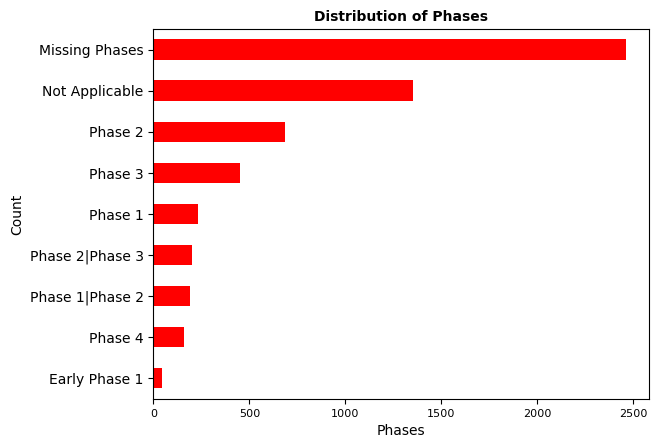

In [35]:
data['Phases'].value_counts().sort_values(ascending=True).plot(kind='barh',color='red')
plt.title('Distribution of Phases', fontsize=10, fontweight='bold')
plt.xlabel('Phases', fontsize=10)
plt.ylabel('Count', fontsize=10)
plt.xticks(fontsize=8)
plt.show()

In [36]:
data['Gender'].value_counts()

Gender
All               5567
Female             162
Male                44
Missing Gender      10
Name: count, dtype: int64

In [37]:
data['Age'].value_counts()

Age
18 Years and older   (Adult, Older Adult)           2885
Child, Adult, Older Adult                            486
18 Years to 80 Years   (Adult, Older Adult)          221
18 Years to 65 Years   (Adult, Older Adult)          155
18 Years to 75 Years   (Adult, Older Adult)          135
                                                    ... 
15 Years to 45 Years   (Child, Adult)                  1
1 Month to 30 Years   (Child, Adult)                   1
21 Years to 40 Years   (Adult)                         1
11 Years and older   (Child, Adult, Older Adult)       1
8 Years to 20 Years   (Child, Adult)                   1
Name: count, Length: 417, dtype: int64

In [38]:
def extract_age_range(age):
    if 'Years to' in age:
        age_range = age.split(' to ')
        return int(age_range[0].split(' ')[0]), int(age_range[1].split(' ')[0])
    
    elif 'and older' in age:
        min_age = int(age.split(' ')[0])
        return min_age, np.inf 
    
    elif 'Child' in age:
        return 0, 18  
    elif 'Adult' in age:
        return 18, 65  
    elif 'Older Adult' in age:
        return 65, 100 
    else:
        return np.nan, np.nan  

data[['Age_min', 'Age_max']] = data['Age'].apply(lambda x: pd.Series(extract_age_range(x)))
print(data[['Age', 'Age_min', 'Age_max']].head(10))

                                                Age  Age_min  Age_max
0         18 Years and older   (Adult, Older Adult)     18.0      inf
1         18 Years and older   (Adult, Older Adult)     18.0      inf
2         18 Years and older   (Adult, Older Adult)     18.0      inf
3                         Child, Adult, Older Adult      0.0     18.0
4                    18 Years to 48 Years   (Adult)     18.0     48.0
5       18 Years to 75 Years   (Adult, Older Adult)     18.0     75.0
6                    18 Years to 45 Years   (Adult)     18.0     45.0
7       18 Years to 99 Years   (Adult, Older Adult)     18.0     99.0
8                    18 Years to 55 Years   (Adult)     18.0     55.0
9  15 Years and older   (Child, Adult, Older Adult)     15.0      inf


Age Category
Adolescent    4525
Child         1008
Adult          133
Senior         116
Name: count, dtype: int64


C:\Users\91700\AppData\Local\Temp\ipykernel_12136\4230206594.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=data['Age Category'], palette='bright')


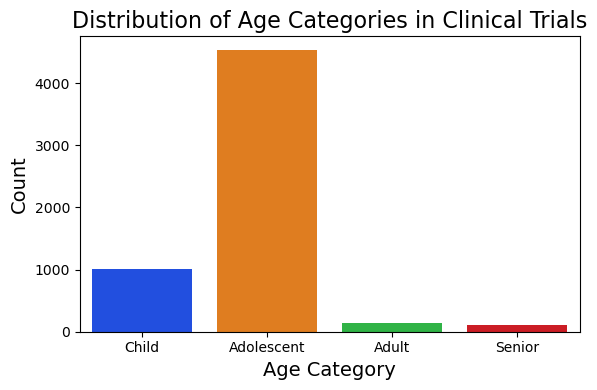

In [39]:
bins = [0, 18, 35, 60, 100]  
labels = ['Child', 'Adolescent', 'Adult', 'Senior']

data['Age Category'] = pd.cut(data['Age_min'], bins=bins, labels=labels, right=False)
print(data['Age Category'].value_counts())

plt.figure(figsize=(6, 4))
sns.countplot(x=data['Age Category'], palette='bright')
plt.title('Distribution of Age Categories in Clinical Trials', fontsize=16)
plt.xlabel('Age Category', fontsize=14)
plt.ylabel('Count', fontsize=14)
plt.tight_layout()
plt.show()

In [40]:
data['Study Results'].value_counts()

Study Results
No Results Available    5747
Has Results               36
Name: count, dtype: int64

<Axes: xlabel='Study Results', ylabel='count'>

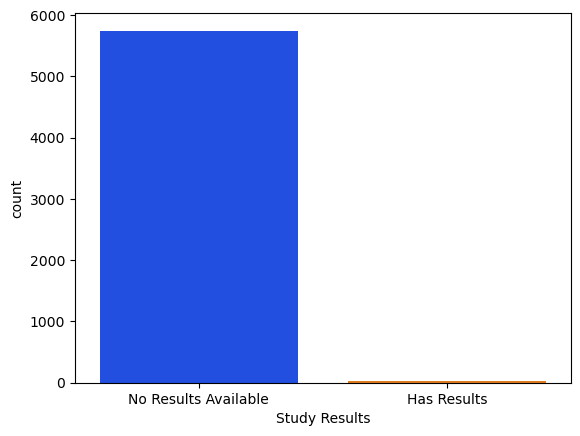

In [41]:
sns.countplot(x='Study Results', data=data, palette = 'bright', hue ='Study Results')

In [42]:
data.head()

,Rank,NCT Number,Title,Acronym,Status,Study Results,Conditions,Interventions,Outcome Measures,Sponsor/Collaborators,...,Start Date,Primary Completion Date,Completion Date,First Posted,Last Update Posted,Locations,URL,Age_min,Age_max,Age Category
0,1,NCT04785898,Diagnostic Performance of the ID Now™ COVID-19...,COVID-IDNow,"Active, not recruiting",No Results Available,Covid19,Diagnostic Test: ID Now™ COVID-19 Screening Test,Evaluate the diagnostic performance of the ID ...,Groupe Hospitalier Paris Saint Joseph,...,"November 9, 2020","December 22, 2020","April 30, 2021","March 8, 2021","March 8, 2021","Groupe Hospitalier Paris Saint-Joseph, Paris, ...",https://ClinicalTrials.gov/show/NCT04785898,18.0,inf,Adolescent
1,2,NCT04595136,Study to Evaluate the Efficacy of COVID19-0001...,COVID-19,Not yet recruiting,No Results Available,SARS-CoV-2 Infection,Drug: Drug COVID19-0001-USR|Drug: normal saline,Change on viral load results from baseline aft...,United Medical Specialties,...,"November 2, 2020","December 15, 2020","January 29, 2021","October 20, 2020","October 20, 2020","Cimedical, Barranquilla, Atlantico, Colombia",https://ClinicalTrials.gov/show/NCT04595136,18.0,inf,Adolescent
2,3,NCT04395482,Lung CT Scan Analysis of SARS-CoV2 Induced Lun...,TAC-COVID19,Recruiting,No Results Available,covid19,Other: Lung CT scan analysis in COVID-19 patients,A qualitative analysis of parenchymal lung dam...,University of Milano Bicocca,...,"May 7, 2020","June 15, 2021","June 15, 2021","May 20, 2020","November 9, 2020","Ospedale Papa Giovanni XXIII, Bergamo, Italy|P...",https://ClinicalTrials.gov/show/NCT04395482,18.0,inf,Adolescent
3,4,NCT04416061,The Role of a Private Hospital in Hong Kong Am...,COVID-19,"Active, not recruiting",No Results Available,COVID,Diagnostic Test: COVID 19 Diagnostic Test,Proportion of asymptomatic subjects|Proportion...,Hong Kong Sanatorium & Hospital,...,"May 25, 2020","July 31, 2020","August 31, 2020","June 4, 2020","June 4, 2020","Hong Kong Sanatorium & Hospital, Hong Kong, Ho...",https://ClinicalTrials.gov/show/NCT04416061,0.0,18.0,Child
4,5,NCT04395924,Maternal-foetal Transmission of SARS-Cov-2,TMF-COVID-19,Recruiting,No Results Available,Maternal Fetal Infection Transmission|COVID-19...,Diagnostic Test: Diagnosis of SARS-Cov2 by RT-...,COVID-19 by positive PCR in cord blood and / o...,Centre Hospitalier Régional d'Orléans|Centre d...,...,"May 5, 2020",May 2021,May 2021,"May 20, 2020","June 4, 2020","CHR Orléans, Orléans, France",https://ClinicalTrials.gov/show/NCT04395924,18.0,48.0,Adolescent
